# memoryGAN: classical key lookup vs. Iterative Quantum Amplitude Estimation

This notebook trains and tests two memoryGANs (Kim, Kim & Kim, ICLR 2018). Their discriminators differ as follows; **each model also runs in the configuration that worked best for it**, see below:

| | baseline (`mgan.Memory`) | AE variant (`QAEMemory`, defined below) |
|---|---|---|
| key encoding | unit-norm float vector $k\in\mathbb{R}^{D}$ | $L$-bit SimHash code $b(k)_j = [k\cdot p_j > 0]$, stored in QRAM as angles $\pi b_j$ |
| key search | cosine similarity $q\cdot k$ against every slot | Hamming-radius test $\mathrm{Ham}(b(q), b(k)) \le r$, evaluated coherently by the oracle |
| discriminator output | vMF mixture: posterior mass $\propto h_i\,e^{\kappa q\cdot k_i}$ on the top-k real slots | $\log(\hat c_{real}+\beta) - \log(\hat c_{fake}+\beta)$, where $\hat c$ are **IQAE** neighbour counts |
| gradient to the encoder | exact | straight-through: forward = IQAE estimate, backward = sigmoid-relaxed count |

The AE code is loaded **unchanged** from `amplitude_estimation/sample.ipynb` (its library cells, sections 1-5), a verbatim copy of the
standalone `amplitude_estimation` project's notebook that is vendored into this repo.
It is *Iterative* QAE (Grinko et al. 2019, Chernoff-Hoeffding intervals) with three backends that share one interface:
`qram` (full coherent circuit), `stateprep` (classical flags folded into one state preparation) and `analytic`
(exact ideal-device measurement statistics, $P(1\mid k)=\sin^2((2k+1)\theta)$). Training uses `analytic`, because
simulating the QRAM circuit for 4096 slots would need 19 qubits and roughly 260k gates per Grover iterate. Section 6 then
re-runs a slice of the trained memory on the real `qram` circuit to check that both backends agree.

**Two configurations.** Each model uses the setup that trained best for it; with the other's setup it fails.

| | baseline (package defaults, `mgan/config.py`) | QAE (`QAE_CONFIG` below) |
|---|---|---|
| memory write | the paper's incremental EM on the top-128 same-label slots, histogram prior $h$ | nearest slot: merge if same label, else replace the oldest (`NearestSlotMemory`) |
| keys for the generator | drawn $\propto h$ | uniform over real slots |
| MI term, weight | paper's $-\kappa\,k\cdot\mu(G(z,k))$, 0.01 | contrastive $-\log p(\text{slot}\mid G(z,k))$, 1.0 |
| key size / noise size / conv width / k | 256 / 16 / 64 / 128 | 128 / 64 / 32 / 16 |

The reason both cannot share one setup is in section 8: the paper's EM update collapses all live keys onto one real
and one fake vector, which a cosine discriminator survives (it becomes a plain linear real/fake head) but a
Hamming-radius count cannot. The nearest-slot memory keeps thousands of distinct keys, which the count needs.

**What is quantum.** `QAEMemory` overrides only `real_logit`, the discriminator's real/fake decision. The write rule,
key sampling and the MI term stay classical. IQAE returns a *count*, not slot indices or a per-slot distribution, so
it cannot stand in for those.

Runs on Linux/WSL with PennyLane + Catalyst, or on Windows with `pennylane`, `pennylane-lightning` and
`jax` (Catalyst has no Windows build; see section 1). Set `MGAN_STEPS` in the environment to override the number of
training steps.

## 0. Setup

In [1]:
import copy
import dataclasses
import importlib.util
import json
import os
import sys
import time
import traceback
import types
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.utils import make_grid

REPO = Path.cwd().resolve()
while not (REPO / "mgan").is_dir():           # works whether the kernel starts in the repo or a subfolder
    REPO = REPO.parent
AE_NOTEBOOK = REPO / "amplitude_estimation" / "sample.ipynb"   # vendored copy of the AE project notebook
sys.path.insert(0, str(REPO))

from mgan import Memory, MemoryGAN, MemoryGANConfig
from mgan.data import images_only, mnist_loader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
STEPS = int(os.environ.get("MGAN_STEPS", 3000))   # training steps per model
LOG_EVERY = max(1, STEPS // 60)
TRAIN = True     # False: reload the checkpoints written by a previous run
RUN_QRAM = True  # section 6: compile and run the coherent QRAM circuit (~1 min)

config = MemoryGANConfig(device=DEVICE,             # paper / tuned defaults, see mgan/config.py
                         data_root=REPO / "data",       # the default D:\M-GAN paths are Windows-only
                         output_root=REPO / "outputs")
# The QAE model's best configuration (the setup of the earlier run that reached Frechet 60): the repo's original sizes and
# the contrastive MI term at weight 1.0. Its memory rules are NearestSlotMemory, section 3.
QAE_CONFIG = dataclasses.replace(config, feature_dim=128, neighbours=16, kappa=10.0, latent_dim=64, base_channels=32,
                                 mi_form="contrastive", mi_weight=1.0)
CONFIGS = {"baseline": config, "qae": QAE_CONFIG}
config.output_root.mkdir(parents=True, exist_ok=True)
print(f"device={DEVICE}, steps={STEPS}, batch={config.batch_size}")
for tag, c in CONFIGS.items():
    print(f"  {tag:9s} memory={c.memory_slots}x{c.feature_dim}, kappa={c.kappa}, k={c.neighbours}, z={c.latent_dim}, "
          f"width={c.base_channels}, mi={c.mi_form} x {c.mi_weight}")

device=cpu, steps=3000, batch=64
  baseline  memory=4096x256, kappa=10.0, k=128, z=16, width=64, mi=cosine x 0.01
  qae       memory=4096x128, kappa=10.0, k=16, z=64, width=32, mi=contrastive x 1.0


## 1. Load the IQAE implementation

All code cells from `sample.ipynb` before its "6. Demo" section are executed into a module `ae`. That gives
`LSHHamming`, `QAEMemoryCounter`, `iqae`, the QRAM circuit builders and the samplers. Nothing in the source notebook
is modified.

In [2]:
def load_notebook_module(path: Path, name: str, stop_at: str) -> types.ModuleType:
    # The source notebook has a non-UTF-8 byte in a markdown cell; code cells are plain ASCII.
    nb = json.loads(path.read_bytes().decode("utf-8", errors="replace"))
    sources = []
    for cell in nb["cells"]:
        text = "".join(cell["source"])
        if cell["cell_type"] == "markdown" and text.lstrip().startswith(stop_at):
            break
        if cell["cell_type"] == "code":
            sources.append(text)
    module = types.ModuleType(name)
    module.__file__ = str(path)
    sys.modules[name] = module            # dataclasses look their module up here
    exec(compile("\n\n".join(sources), str(path), "exec"), module.__dict__)
    return module


# Catalyst has no Windows build. The AE code imports it at the top but only uses it when use_catalyst=True, so an
# empty placeholder lets the code load (removed again right after, so PennyLane never sees it); circuits then run
# uncompiled through plain PennyLane. JAX is still imported by the AE code; it has Windows wheels.
HAS_CATALYST = importlib.util.find_spec("catalyst") is not None
if not HAS_CATALYST:
    sys.modules["catalyst"] = types.ModuleType("catalyst")
try:
    ae = load_notebook_module(AE_NOTEBOOK, "ae_iqae", stop_at="## 6. Demo")
finally:
    if not HAS_CATALYST:
        del sys.modules["catalyst"]
print(f"Catalyst available: {HAS_CATALYST}; loaded from", AE_NOTEBOOK.name, "->", [n for n in ("LSHHamming", "QAEMemoryCounter", "iqae", "QRAMLayout") if hasattr(ae, n)])

Catalyst available: False; loaded from sample.ipynb -> ['LSHHamming', 'QAEMemoryCounter', 'iqae', 'QRAMLayout']


## 2. The two encodings

**Baseline.** The encoder emits a unit-norm $q\in\mathbb{R}^{D}$ ($D=256$). Every slot stores a float key and a histogram
weight $h_i$, and the discriminator looks at all slots: $p(\text{real}\mid q)$ is the posterior weight
$\propto h_i\, e^{\kappa\, q\cdot k_i}$ that falls on real slots.

**AE.** Embeddings ($D=128$ in the QAE configuration) are hashed to $L$ sign bits of random projections (SimHash). For two vectors at angle $\theta$, each
bit differs with probability $\theta/\pi$, so $\mathbb{E}[\mathrm{Ham}]/L = \theta/\pi$ and a Hamming radius $r$ is
roughly a cosine threshold $\cos(\pi r/L)$. The state preparation is

$$A|0\rangle = \tfrac{1}{\sqrt M}\sum_i |i\rangle\,|\,[\mathrm{Ham}(b_i, b_q)\le r]\,\rangle_{\text{flag}},\qquad a = P(\text{flag}=1)=\tfrac{\#\text{neighbours}}{M}.$$

IQAE estimates $a$ to $\pm\,\varepsilon_{count}/M$ with confidence $1-\alpha$. We run it once over the real slots and once
over the fake slots, which gives $\hat c_{real}$ and $\hat c_{fake}$. The logit uses additive smoothing $\beta$, so an
empty neighbourhood gives $p = 0.5$ instead of $\log 0$.

The QAE memory **keeps the float keys** as its stored state and hashes them on every call. The generator still needs
real-valued keys (`read_keys`), the EM update averages keys, and the QRAM circuit takes the codes as runtime angles
anyway, so this costs no recompiles.

The plot below checks the SimHash property in $D=128$ and shows the cosine threshold each radius corresponds to.

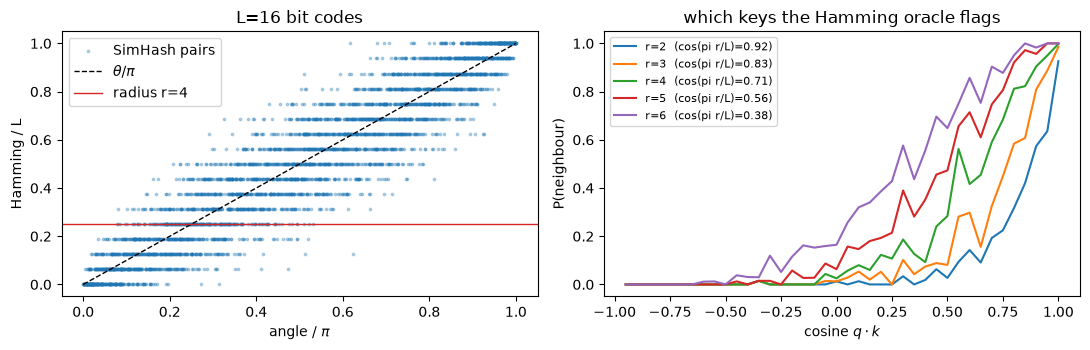

two random 128-d unit vectors: mean cosine 0.069, P(neighbour at r=4) = 0.046


In [3]:
L_BITS, RADIUS = 16, 4
D_QAE = QAE_CONFIG.feature_dim
matcher_demo = ae.LSHHamming(D_QAE, n_bits=L_BITS, radius_bits=RADIUS, seed=0)

g = torch.Generator().manual_seed(1)
a = F.normalize(torch.randn(4000, D_QAE, generator=g), dim=1)
# pairs spread over all angles: b = cos(t) a + sin(t) a_perp
t = torch.rand(4000, generator=g) * torch.pi
perp = F.normalize(torch.randn(4000, D_QAE, generator=g), dim=1)
perp = F.normalize(perp - (perp * a).sum(1, keepdim=True) * a, dim=1)
b = torch.cos(t)[:, None] * a + torch.sin(t)[:, None] * perp
ham = (matcher_demo.codes(a) != matcher_demo.codes(b)).sum(1).float()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(t / torch.pi, ham / L_BITS, s=3, alpha=0.3, label="SimHash pairs")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label=r"$\theta/\pi$")
ax[0].axhline(RADIUS / L_BITS, color="C3", lw=1, label=f"radius r={RADIUS}")
ax[0].set_xlabel(r"angle / $\pi$"); ax[0].set_ylabel("Hamming / L"); ax[0].legend(); ax[0].set_title(f"L={L_BITS} bit codes")
cos = torch.cos(t)
for r in (2, 3, 4, 5, 6):
    match = (ham <= r).float()
    centers = torch.linspace(-1, 1, 41)
    idx = torch.bucketize(cos, centers)
    curve = [match[idx == i].mean().item() if (idx == i).any() else np.nan for i in range(1, 41)]
    ax[1].plot(centers[1:].numpy(), curve, label=f"r={r}  (cos(pi r/L)={np.cos(np.pi * r / L_BITS):.2f})")
ax[1].set_xlabel(r"cosine $q\cdot k$"); ax[1].set_ylabel("P(neighbour)"); ax[1].legend(fontsize=8)
ax[1].set_title("which keys the Hamming oracle flags")
plt.tight_layout(); plt.show()

rand = F.normalize(torch.randn(2000, D_QAE, generator=g), dim=1)
print(f"two random {D_QAE}-d unit vectors: mean cosine {(rand[:1000] * rand[1000:]).sum(1).abs().mean():.3f}, "
      f"P(neighbour at r={RADIUS}) = {(matcher_demo.hamming(rand[:1000], rand[1000:]).diagonal() <= RADIUS).float().mean():.3f}")

## 3. `QAEMemory`: the replacement

`NearestSlotMemory` restores the repo's previous memory rules (nearest-slot merge/replace, uniform key sampling, slot posterior $\mathrm{softmax}(\kappa\,q\cdot k)$), which keep the stored keys distinct. `QAEMemory` builds on it and overrides only `real_logit`; `real_posterior` (the sigmoid of `real_logit`)
inherits automatically. During the D and G passes the gradient reaches the encoder through `QAEMemoryCounter`'s
surrogate: the forward value is the IQAE estimate, and the backward pass is the derivative of the sigmoid-relaxed count.
The memory also tallies Grover calls so that query cost can be reported.

In [4]:
class NearestSlotMemory(Memory):
    # The repo's previous memory rules (before the paper's EM update was ported). Keeps keys distinct: a write merges
    # into the single nearest slot if it has the same label, otherwise it replaces the oldest slot. The hist buffer of
    # the base class is kept (so state dicts match) but not used.

    @torch.no_grad()
    def write(self, q, is_real):
        for query, label in zip(q, is_real.bool()):
            nearest = self.lookup(query[None], k=1)[0][0, 0]
            if self.values[nearest] == float(label):
                merged = self.keys[nearest] + query
                self.keys[nearest] = F.normalize(merged if merged.norm() > 1e-6 else query, dim=0)
                self.ages[nearest] = 0
            else:
                self._replace(self._oldest_slot(), query, label)
        self.ages += 1

    def real_logit(self, q):
        # dense vMF mixture without a histogram prior (QAEMemory overrides this; kept for the comparison in section 6)
        scores = self.kappa * self.similarity(q)
        is_real = (self.values == 1.0)[None]
        return (torch.logsumexp(scores.masked_fill(~is_real, float("-inf")), dim=1)
                - torch.logsumexp(scores.masked_fill(is_real, float("-inf")), dim=1))

    def slot_posterior(self, q):
        return F.softmax(self.kappa * self.similarity(q), dim=1)

    def sample_real_keys(self, n):
        real_slots = (self.values == 1.0).nonzero(as_tuple=True)[0]
        if real_slots.numel() == 0:
            raise RuntimeError("memory has no real slots to sample from")
        indices = real_slots[torch.randint(real_slots.numel(), (n,), device=real_slots.device)]
        return self.read_keys(indices), indices


class QAEMemory(NearestSlotMemory):
    # Memory whose real/fake decision is an IQAE neighbour count over LSH codes.

    def __init__(self, slots, dim, neighbours=16, kappa=10.0, *, n_bits=16, radius_bits=4, count_eps=0.5,
                 alpha=0.05, shots=1024, backend="analytic", prior=1.0, seed=0):
        super().__init__(slots, dim, neighbours, kappa)
        self.matcher = ae.LSHHamming(dim, n_bits=n_bits, radius_bits=radius_bits, seed=seed)
        self.counter = ae.QAEMemoryCounter(self.matcher, count_eps=count_eps, alpha=alpha, shots=shots,
                                           backend=backend, seed=seed)
        self.prior = prior
        self.grover_calls = 0      # running totals, for cost reporting
        self.queries = 0

    def neighbour_counts(self, q):
        # IQAE estimates of how many real / fake slots lie within the Hamming radius of each query.
        is_real = self.values == 1.0
        return self.counter(q, self.keys[is_real]), self.counter(q, self.keys[~is_real])

    def real_logit(self, q):
        real, fake = self.neighbour_counts(q)
        self.grover_calls += int(real.grover_calls.sum() + fake.grover_calls.sum())
        self.queries += q.shape[0]
        return torch.log(real.count + self.prior) - torch.log(fake.count + self.prior)


QAE_KW = dict(n_bits=L_BITS, radius_bits=RADIUS, count_eps=0.5, alpha=0.05, shots=1024, backend="analytic", prior=1.0)


def build(tag: str, seed: int = SEED) -> MemoryGAN:
    # Each model is built from its own config; the same seed gives the same initial weights for equal sizes.
    torch.manual_seed(seed)
    cfg = CONFIGS[tag]
    model = MemoryGAN(cfg)
    if tag == "qae":
        qae = QAEMemory(cfg.memory_slots, cfg.feature_dim, cfg.neighbours, cfg.kappa, **QAE_KW)
        qae.load_state_dict(model.memory.state_dict())   # same initial keys/values/ages
        model.discriminator.memory = qae.to(cfg.device)
    return model

### Contract tests

The repo's `tests/test_memory.py` is written to be run against a replacement memory. Here every test runs on both
classes, using the test file's own sizes ($N=32$, $D=8$, $k=4$). Failures are reported rather than raised, because
some of them are expected: IQAE is a *stochastic* estimator, so two calls on the same query need not return identical
logits.

In [5]:
# loaded by path: a stray site-packages "tests" package (some pip packages ship one) would shadow the repo's tests/
_spec = importlib.util.spec_from_file_location("mgan_contract_tests", REPO / "tests" / "test_memory.py")
contract = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(contract)

factories = {
    "baseline": contract.classical,
    "qae": lambda: (torch.manual_seed(0), QAEMemory(contract.SLOTS, contract.DIM, neighbours=contract.K, kappa=10.0,
                                                    **{**QAE_KW, "n_bits": 8, "radius_bits": 2}))[1],
}
tests = [(name, fn) for name, fn in vars(contract).items() if name.startswith("test_") and callable(fn)]
results, failures = {}, []
for name, fn in tests:
    row = {}
    for label, factory in factories.items():
        torch.manual_seed(1)
        try:
            fn(factory()); row[label] = "pass"
        except contract.pytest.skip.Exception:         # e.g. the dense-only gradient test on a top-k memory
            row[label] = "skip"
        except Exception as e:
            row[label] = "FAIL" if isinstance(e, AssertionError) else f"ERROR {type(e).__name__}"
            frame = traceback.extract_tb(e.__traceback__)[-1]
            failures.append(f"{label}: {name}, line {frame.lineno}: {frame.line}")
    results[name] = row
print(f"{'test':58s} {'baseline':>9s} {'qae':>9s}")
for name, row in results.items():
    print(f"{name:58s} {row['baseline']:>9s} {row['qae']:>9s}")
print("\n".join(["", "failed assertions:"] + failures) if failures else "\nall passed")

test                                                        baseline       qae
test_initial_state                                              pass      pass
test_lookup_sorted_and_differentiable                           pass      pass
test_lookup_k_clamped_to_slots                                  pass      pass
test_read_keys_returns_unit_norm_copies                         pass      pass
test_write_moves_nearest_slot_toward_query                      pass      pass
test_write_merges_into_nearest_same_label                       pass      pass
test_write_replaces_oldest_when_no_label_match                  pass      pass
test_write_ages_every_slot_once_per_call                        pass      pass
test_write_rows_are_sequential                                  pass      pass
test_keys_stay_unit_norm_after_writes                           pass      pass
test_real_posterior_bounds_and_gradient                         pass      FAIL
test_real_logit_has_gradient_when_neighbours_all_fak

## 4. Training

Both models see the same MNIST stream (same seed); their sizes differ (see the configuration table above). Losses are averaged
over `LOG_EVERY` steps. Each model is checkpointed to `outputs/` so that sections 5-8 can be re-run with `TRAIN = False`.

In [6]:
def train(model: MemoryGAN, steps: int, tag: str) -> dict:
    torch.manual_seed(SEED)
    loader = mnist_loader(config.data_root, config.batch_size)
    batches = iter(loader)
    hist, acc, n = defaultdict(list), defaultdict(float), 0
    t_start = t_log = time.perf_counter()
    for step in range(1, steps + 1):
        try:
            batch = next(batches)
        except StopIteration:
            batches = iter(loader); batch = next(batches)
        for k, v in model.train_step(images_only(batch)).items():
            acc[k] += v
        n += 1
        if step % LOG_EVERY == 0 or step == steps:
            now = time.perf_counter()
            hist["step"].append(step)
            for k, v in acc.items():
                hist[k].append(v / n)
            hist["sec_per_step"].append((now - t_log) / n)
            acc, n, t_log = defaultdict(float), 0, now
            if step % (LOG_EVERY * 20) == 0 or step == steps:
                print(f"[{tag}] step {step:5d}  " + "  ".join(f"{k}={hist[k][-1]:.3f}" for k in ("loss_d", "loss_g_adv", "loss_g_mi"))
                      + f"  {hist['sec_per_step'][-1]:.3f}s/step")
    hist["total_sec"] = time.perf_counter() - t_start
    return dict(hist)


models, histories = {}, {}
for tag in ("baseline", "qae"):
    cfg = CONFIGS[tag]
    run = f"{tag}_{STEPS}_{cfg.mi_form}{cfg.mi_weight:g}_d{cfg.feature_dim}"
    ckpt, hfile = config.output_root / f"{run}.pt", config.output_root / f"{run}_history.json"
    models[tag] = build(tag)
    if TRAIN or not ckpt.exists():
        histories[tag] = train(models[tag], STEPS, tag)
        torch.save(models[tag].state_dict(), ckpt)
        hfile.write_text(json.dumps(histories[tag]))
    else:
        models[tag].load_state_dict(torch.load(ckpt, map_location=DEVICE))
        histories[tag] = json.loads(hfile.read_text())
    print(f"[{tag}] {histories[tag]['total_sec']:.0f}s total")

[baseline] step  1000  loss_d=0.422  loss_g_adv=3.029  loss_g_mi=-8.726  0.148s/step
[baseline] step  2000  loss_d=0.091  loss_g_adv=4.544  loss_g_mi=-8.343  0.148s/step
[baseline] step  3000  loss_d=0.168  loss_g_adv=3.427  loss_g_mi=-8.754  0.147s/step
[baseline] 445s total
[qae] step  1000  loss_d=1.580  loss_g_adv=1.388  loss_g_mi=3.114  0.111s/step
[qae] step  2000  loss_d=0.935  loss_g_adv=1.623  loss_g_mi=2.823  0.109s/step


C:\Users\sammy\PycharmProjects\AEM-GAN\amplitude_estimation\sample.ipynb:415: UserWarning: IQAE hit max_rounds=1100; returning current interval.
  "\n",


[qae] step  3000  loss_d=0.916  loss_g_adv=1.784  loss_g_mi=2.739  0.107s/step
[qae] 328s total


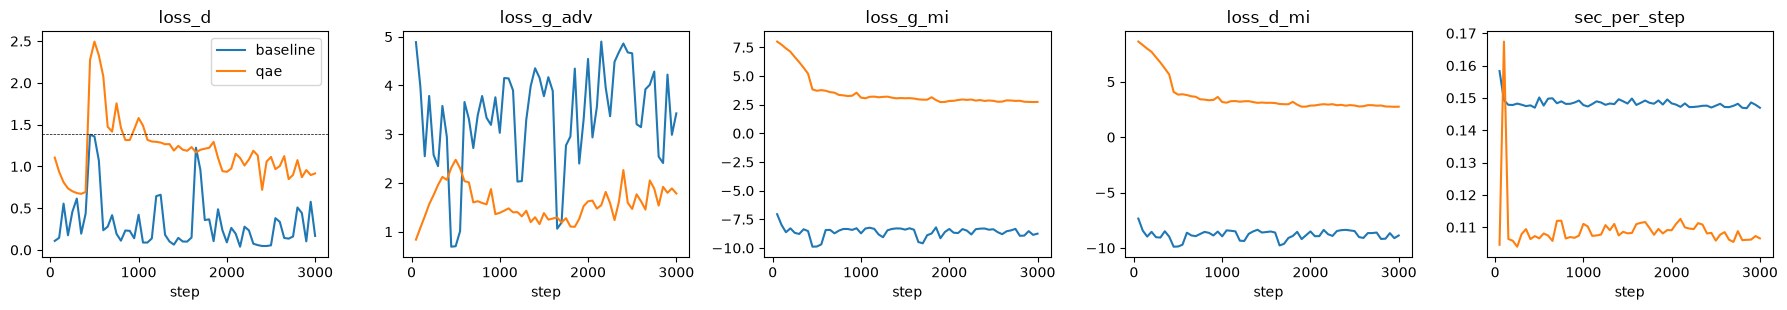

In [7]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.2))
for i, key in enumerate(("loss_d", "loss_g_adv", "loss_g_mi", "loss_d_mi", "sec_per_step")):
    for tag, h in histories.items():
        ax[i].plot(h["step"], h[key], label=tag)
    ax[i].set_title(key); ax[i].set_xlabel("step")
ax[0].axhline(2 * np.log(2), color="k", lw=0.5, ls="--")     # loss_d of a discriminator at chance
ax[0].legend(); plt.tight_layout(); plt.show()

## 5. Samples

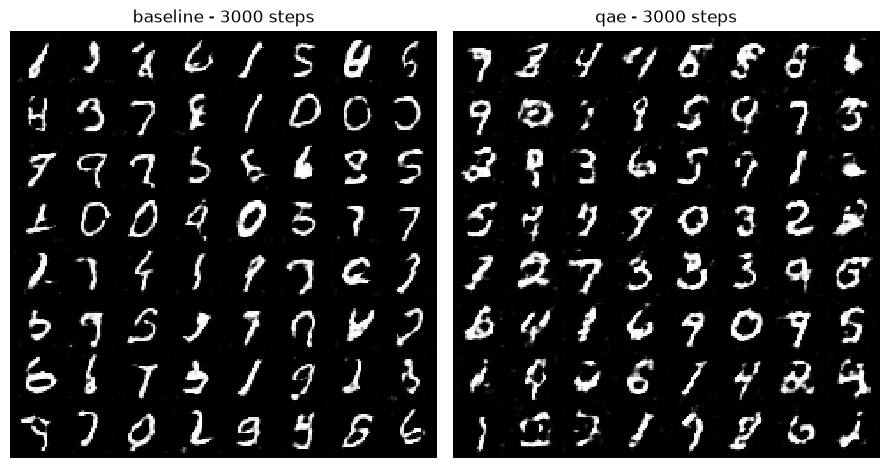

In [8]:
def show_grid(images, title, ax):
    grid = make_grid(images[:64].cpu(), nrow=8, normalize=True, value_range=(-1, 1))
    ax.imshow(grid.permute(1, 2, 0), interpolation="nearest"); ax.set_title(title); ax.axis("off")


torch.manual_seed(123)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6))
for a_, tag in zip(ax, models):
    show_grid(models[tag].generate(64), f"{tag} - {STEPS} steps", a_)
plt.tight_layout(); plt.show()

## 6. Evaluation

Helpers, then compute (no output), then all metrics as tables, then the IQAE plot.

| table | metrics | measured on |
|---|---|---|
| Sample quality | Fréchet ↓, Inception score ↑, % per digit | 10k samples vs. MNIST test set, in a small MNIST classifier's feature space |
| Training & discriminator | final losses, s/step, D ROC-AUC, D accuracy, mean p(real), ms/query | 1k test digits vs. 1k samples (D in batch-norm train mode, batches of 64) |
| Memory health | slots written, live/distinct real keys, cos(μ(G(z,k)), k), gradient norms, LSH codes | trained memory; one batch of 64 |
| IQAE fidelity | count error, CI coverage, Grover calls, decision agreement | 250 real + 250 generated queries, trained QAE memory |
| QRAM spot check | IQAE counts on the `qram` circuit vs. `analytic` vs. exact | 3 real + 3 generated queries, 32 + 32 nearest slots (12 qubits) |

In [9]:
from scipy import linalg


class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Linear(128, 10)

    def forward(self, x):
        return self.head(self.features(x))


@torch.no_grad()
def clf_stats(images):
    feats, probs = [], []
    for chunk in images.split(1000):
        h = clf.features(chunk)
        feats.append(h.double().cpu()); probs.append(F.softmax(clf.head(h), 1).double().cpu())
    return torch.cat(feats).numpy(), torch.cat(probs).numpy()


def frechet(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))


def inception_score(p):
    py = p.mean(0, keepdims=True)
    return float(np.exp((p * (np.log(p + 1e-12) - np.log(py + 1e-12))).sum(1).mean()))


@torch.no_grad()
def generate_many(model, n, batch=1000):
    return torch.cat([model.generate(batch) for _ in range(n // batch)])


@torch.no_grad()
def d_logits(model, images, batch=64):
    # The encoder's batch norm only ever ran in train mode, on pure-real or pure-fake batches of 64, so it is
    # evaluated the same way. A copy is used so the running statistics of the trained model are not touched.
    d = copy.deepcopy(model.discriminator).train()
    return torch.cat([d(chunk) for chunk in images.split(batch)]).float().cpu()


@torch.no_grad()
def encode(model, images, batch=64):
    # same batch-norm regime as d_logits: train mode, pure batches, on a copy
    enc = copy.deepcopy(model.discriminator.encoder).train()
    return torch.cat([enc(chunk) for chunk in images.split(batch)])


def auc(pos, neg):
    # P(score_real > score_fake), ties count half
    diff = pos[:, None] - neg[None, :]
    return float((diff > 0).float().mean() + 0.5 * (diff == 0).float().mean())


def grad_norm(params):
    return sum(float((p.grad ** 2).sum()) for p in params if p.grad is not None) ** 0.5


def distinct_directions(keys, cos_max=0.866):
    # greedy count of keys that are more than 30 degrees from every key already counted
    kept = keys[:0]
    for k in keys:
        if len(kept) == 0 or (kept @ k).max() < cos_max:
            kept = torch.cat([kept, k[None]])
    return len(kept)


def memory_health(model, real):
    m = copy.deepcopy(model)                      # gradients and batch norm must not touch the trained model
    D, G, mem = m.discriminator, m.generator, m.memory
    written, is_real_slot = mem.ages < STEPS, mem.values == 1.0
    live_real = mem.keys[is_real_slot & (mem.ages < 100)]          # real slots touched in the last 100 steps
    _, sampled = mem.sample_real_keys(4096)
    keys, slots = mem.sample_real_keys(len(real))
    fake = G(torch.randn(len(real), m.config.latent_dim, device=DEVICE), keys)
    ones, zeros = torch.ones(len(real), device=DEVICE), torch.zeros(len(real), device=DEVICE)

    (F.binary_cross_entropy_with_logits(D(real), ones)
     + F.binary_cross_entropy_with_logits(D(fake.detach()), zeros)).backward()
    enc = grad_norm(D.encoder.parameters())
    G.zero_grad()
    F.binary_cross_entropy_with_logits(D(fake), ones).backward(retain_graph=True)
    g_adv = grad_norm(G.parameters())
    G.zero_grad()
    (m.config.mi_weight * m.mutual_information(fake, keys, slots)).backward()
    g_mi = grad_norm(G.parameters())

    matcher = getattr(mem, "matcher", None) or ae.LSHHamming(m.config.feature_dim, n_bits=L_BITS, radius_bits=RADIUS)
    with torch.no_grad():
        mu = D.encoder(fake)
        cos_own, cos_shuf = (mu * keys).sum(1).mean(), (mu * keys.roll(1, 0)).sum(1).mean()
        codes = lambda x: len({tuple(r) for r in matcher.codes(D.encoder(x)).cpu().tolist()})
        n_codes_real, n_codes_fake = codes(real), codes(fake)
    return {"slots ever written": f"{int(written.sum())}/{mem.n_slots}",
            "real / fake slots": f"{int(is_real_slot.sum())} / {int((~is_real_slot).sum())}",
            "live real keys / distinct (>30°)": f"{len(live_real)} / {distinct_directions(live_real)}",
            "sampled keys from written slots": f"{float(written[sampled].float().mean()):.1%}",
            "cos(μ(G(z,k)), k): own / random key": f"{cos_own:.2f} / {cos_shuf:.2f}",
            "‖∇‖ encoder": f"{enc:.3f}",
            "‖∇‖ G: adversarial / MI": f"{g_adv:.3f} / {g_mi:.3f}",
            "LSH codes in 64 real / 64 fake": f"{n_codes_real} / {n_codes_fake}"}


torch.manual_seed(SEED)
clf = MNISTNet().to(DEVICE)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for epoch in range(2):
    for x, y in mnist_loader(config.data_root, 128):
        loss = F.cross_entropy(clf(x.to(DEVICE)), y.to(DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
test_x, test_y = [], []
for x, y in mnist_loader(config.data_root, 1000, train=False):
    test_x.append(x); test_y.append(y)
test_x, test_y = torch.cat(test_x).to(DEVICE), torch.cat(test_y).to(DEVICE)
with torch.no_grad():
    clf_acc = float((clf(test_x).argmax(1) == test_y).float().mean())

In [10]:
import warnings

# 1. sample quality
N_EVAL = 10000
torch.manual_seed(7)
real_f, real_p = clf_stats(test_x)
generated = {tag: generate_many(m, N_EVAL) for tag, m in models.items()}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", linalg.LinAlgWarning)    # near-singular covariances of collapsed samples
    quality = {"real test set": (frechet(real_f[:5000], real_f[5000:]), inception_score(real_p), real_p.argmax(1))}
    for tag, imgs in generated.items():
        f, p = clf_stats(imgs)
        quality[tag] = (frechet(f, real_f), inception_score(p), p.argmax(1))

# 2. discriminator
N_D = 1000
real_imgs = test_x[torch.randperm(len(test_x), generator=torch.Generator().manual_seed(3))[:N_D]]
disc = {}
for tag, m in models.items():
    t0 = time.perf_counter()
    lr = d_logits(m, real_imgs); lf = d_logits(m, generated[tag][:N_D])
    disc[tag] = dict(auc=auc(lr, lf), acc=float(((lr > 0).float().mean() + (lf <= 0).float().mean()) / 2),
                     p_real=float(torch.sigmoid(lr).mean()), p_fake=float(torch.sigmoid(lf).mean()),
                     ms=(time.perf_counter() - t0) / (2 * N_D) * 1e3)

# 3. memory health
torch.manual_seed(SEED)
health_batch = images_only(next(iter(mnist_loader(config.data_root, config.batch_size)))).to(DEVICE)
health = {tag: memory_health(m, health_batch) for tag, m in models.items()}

# 4. IQAE fidelity inside the trained memory
mem = models["qae"].memory
grover_train = (mem.grover_calls, mem.queries)                     # totals from training, before the calls below
q = torch.cat([encode(models["qae"], real_imgs[:250]), encode(models["qae"], generated["qae"][:250])])
is_real = mem.values == 1.0
out_r, out_f = mem.neighbour_counts(q)
exact_r = mem.matcher.hard(q, mem.keys[is_real]).sum(1).cpu()
exact_f = mem.matcher.hard(q, mem.keys[~is_real]).sum(1).cpu()
est = torch.cat([out_r.count, out_f.count]).cpu()
lo = torch.cat([out_r.count_lower, out_f.count_lower]).cpu()
hi = torch.cat([out_r.count_upper, out_f.count_upper]).cpu()
ex = torch.cat([exact_r, exact_f])
err = (est - ex).abs()
covered = ((lo - 1e-6 <= ex) & (ex <= hi + 1e-6)).float().mean()
calls = torch.cat([out_r.grover_calls, out_f.grover_calls]).float().cpu()
qae_logit = (torch.log(out_r.count + mem.prior) - torch.log(out_f.count + mem.prior)).cpu()
exact_logit = torch.log(exact_r + mem.prior) - torch.log(exact_f + mem.prior)
cos_logit = NearestSlotMemory.real_logit(mem, q).cpu()   # cosine/vMF rule on the same keys

# 5. spot check on the coherent QRAM circuit
spot = None
if RUN_QRAM:
    torch.manual_seed(11)
    q_spot = encode(models["qae"], torch.cat([real_imgs[:3], generated["qae"][:3]]))

    def closest(keys, m):
        h = mem.matcher.hamming(q_spot, keys).min(0).values
        return keys[h.argsort(stable=True)[:m]]

    sub_r, sub_f = closest(mem.keys[is_real], 32), closest(mem.keys[~is_real], 32)
    spot = {"tags": ["real"] * 3 + ["generated"] * 3,
            "exact": (mem.matcher.hard(q_spot, sub_r).sum(1), mem.matcher.hard(q_spot, sub_f).sum(1)),
            "layout": ae.QRAMLayout.for_memory(32, mem.matcher.n_bits, mem.matcher.radius_bits)}
    for backend in ("qram", "analytic"):
        counter = ae.QAEMemoryCounter(mem.matcher, count_eps=0.5, alpha=0.05, shots=1024, backend=backend, seed=0,
                                      use_catalyst=HAS_CATALYST)
        t0 = time.perf_counter()
        spot[backend] = (counter(q_spot, sub_r), counter(q_spot, sub_f), time.perf_counter() - t0)

In [11]:
from IPython.display import Markdown, display


def show(title, header, rows):
    lines = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


show(f"Sample quality ({N_EVAL // 1000}k samples vs. MNIST test; classifier acc {clf_acc:.3f})",
     ["", "Fréchet ↓", "IS ↑"] + [f"% {d}" for d in range(10)],
     [[tag, f"{fd:.1f}", f"{is_:.2f}"] + [f"{h:.0f}" for h in np.bincount(lab, minlength=10) / len(lab) * 100]
      for tag, (fd, is_, lab) in quality.items()])

show(f"Training & discriminator ({N_D} test digits vs. {N_D} samples; loss_d at chance = 1.386)",
     ["", "loss_d", "loss_g_adv", "s/step", "D AUC", "D acc", "p(real): real", "p(real): fake", "ms/query"],
     [[tag, f"{histories[tag]['loss_d'][-1]:.3f}", f"{histories[tag]['loss_g_adv'][-1]:.3f}",
       f"{np.median(histories[tag]['sec_per_step']):.3f}", f"{d['auc']:.3f}", f"{d['acc']:.3f}",
       f"{d['p_real']:.3f}", f"{d['p_fake']:.3f}", f"{d['ms']:.3f}"] for tag, d in disc.items()])

show("Memory health (trained memory; one batch of 64)", ["", *health],
     [[key, *(health[tag][key] for tag in health)] for key in health["baseline"]])

show(f"IQAE fidelity (250 real + 250 generated queries; L={mem.matcher.n_bits}, r={mem.matcher.radius_bits}, "
     f"eps={QAE_KW['count_eps']}, alpha={QAE_KW['alpha']})", ["metric", "value"], [
    ["count error, mean / max (keys)", f"{err.mean():.3f} / {err.max():.3f}"],
    [f"{1 - QAE_KW['alpha']:.0%} CI contains exact count", f"{covered:.3f}"],
    ["Grover calls per count, median / max", f"{calls.median():,.0f} / {calls.max():,.0f}"],
    ["Grover calls per D query, training", f"{grover_train[0] / max(grover_train[1], 1):,.0f}"],
    ["decision agreement: QAE vs exact count", f"{((qae_logit > 0) == (exact_logit > 0)).float().mean():.3f}"],
    ["decision agreement: QAE vs cosine/vMF", f"{((qae_logit > 0) == (cos_logit > 0)).float().mean():.3f}"],
])

if spot:
    (qr, qf, tq), (ar, af, ta) = spot["qram"], spot["analytic"]
    ex_r, ex_f = spot["exact"]
    show(f"QRAM spot check (real / fake neighbour counts; {spot['layout'].n_wires} qubits; qram {tq:.1f} s, analytic {ta:.3f} s)",
         ["query", "exact", "qram", "analytic", "qram 95% CI (real)"],
         [[tag, f"{ex_r[i]:.0f} / {ex_f[i]:.0f}", f"{qr.count[i]:.2f} / {qf.count[i]:.2f}", f"{ar.count[i]:.2f} / {af.count[i]:.2f}",
           f"[{qr.count_lower[i]:.2f}, {qr.count_upper[i]:.2f}]"] for i, tag in enumerate(spot["tags"])])

**Sample quality (10k samples vs. MNIST test; classifier acc 0.984)**

|  | Fréchet ↓ | IS ↑ | % 0 | % 1 | % 2 | % 3 | % 4 | % 5 | % 6 | % 7 | % 8 | % 9 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| real test set | 1.4 | 9.44 | 10 | 11 | 10 | 10 | 10 | 9 | 10 | 10 | 10 | 10 |
| baseline | 57.1 | 6.55 | 14 | 13 | 7 | 9 | 8 | 8 | 9 | 17 | 6 | 9 |
| qae | 70.6 | 6.90 | 12 | 6 | 12 | 12 | 9 | 10 | 8 | 15 | 9 | 7 |

**Training & discriminator (1000 test digits vs. 1000 samples; loss_d at chance = 1.386)**

|  | loss_d | loss_g_adv | s/step | D AUC | D acc | p(real): real | p(real): fake | ms/query |
|---|---|---|---|---|---|---|---|---|
| baseline | 0.168 | 3.427 | 0.148 | 1.000 | 0.998 | 0.987 | 0.002 | 0.073 |
| qae | 0.916 | 1.784 | 0.108 | 0.959 | 0.901 | 0.636 | 0.275 | 0.133 |

**Memory health (trained memory; one batch of 64)**

|  | baseline | qae |
|---|---|---|
| slots ever written | 256/4096 | 4096/4096 |
| real / fake slots | 2048 / 2048 | 1484 / 2612 |
| live real keys / distinct (>30°) | 128 / 1 | 1484 / 1367 |
| sampled keys from written slots | 99.0% | 100.0% |
| cos(μ(G(z,k)), k): own / random key | 0.70 / 0.69 | 0.86 / 0.02 |
| ‖∇‖ encoder | 0.226 | 25.768 |
| ‖∇‖ G: adversarial / MI | 0.817 / 0.184 | 56.306 / 2.382 |
| LSH codes in 64 real / 64 fake | 8 / 11 | 51 / 64 |

**IQAE fidelity (250 real + 250 generated queries; L=16, r=4, eps=0.5, alpha=0.05)**

| metric | value |
|---|---|
| count error, mean / max (keys) | 0.035 / 0.456 |
| 95% CI contains exact count | 0.999 |
| Grover calls per count, median / max | 363,520 / 1,219,584 |
| Grover calls per D query, training | 775,848 |
| decision agreement: QAE vs exact count | 1.000 |
| decision agreement: QAE vs cosine/vMF | 0.674 |

**QRAM spot check (real / fake neighbour counts; 12 qubits; qram 32.9 s, analytic 0.001 s)**

| query | exact | qram | analytic | qram 95% CI (real) |
|---|---|---|---|---|
| real | 1 / 4 | 1.04 / 4.04 | 1.00 / 4.09 | [0.92, 1.16] |
| real | 31 / 27 | 31.05 / 27.05 | 31.01 / 27.01 | [30.94, 31.16] |
| real | 31 / 30 | 30.97 / 30.04 | 31.02 / 29.91 | [30.85, 31.09] |
| generated | 0 / 0 | 0.03 / 0.03 | 0.03 / 0.03 | [0.00, 0.07] |
| generated | 30 / 29 | 29.98 / 28.95 | 30.01 / 28.92 | [29.72, 30.25] |
| generated | 0 / 2 | 0.03 / 1.93 | 0.03 / 1.89 | [0.00, 0.07] |

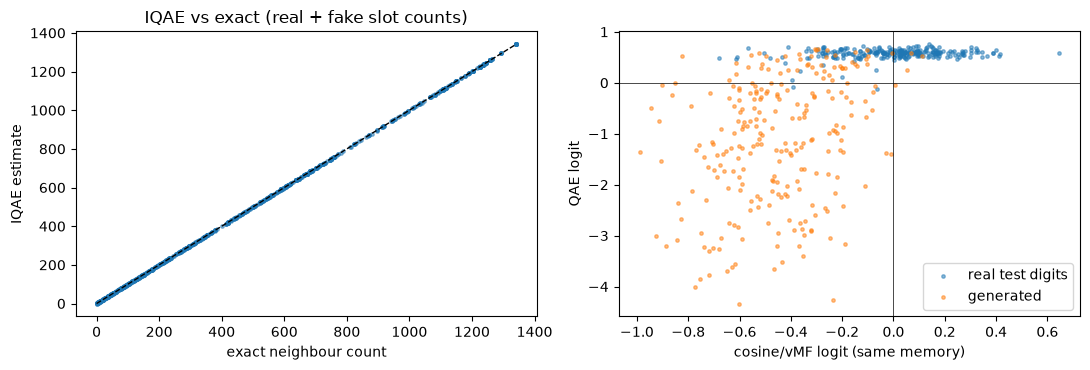

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(ex, est, s=6, alpha=0.5); m_ = float(ex.max()) + 1
ax[0].plot([0, m_], [0, m_], "k--", lw=1); ax[0].set_xlabel("exact neighbour count"); ax[0].set_ylabel("IQAE estimate")
ax[0].set_title("IQAE vs exact (real + fake slot counts)")
ax[1].scatter(cos_logit[:250], qae_logit[:250], s=6, alpha=0.5, label="real test digits")
ax[1].scatter(cos_logit[250:], qae_logit[250:], s=6, alpha=0.5, label="generated")
ax[1].axhline(0, color="k", lw=0.5); ax[1].axvline(0, color="k", lw=0.5)
ax[1].set_xlabel("cosine/vMF logit (same memory)"); ax[1].set_ylabel("QAE logit"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Circuit diagram

PennyLane draws any tape with `qml.drawer.tape_mpl`. The QRAM state preparation $A$ used in section 6 has thousands
of gates, so it is drawn here for a **toy memory**: 4 keys, 2-bit codes, Hamming radius 1. The construction is the
same `ae.qram_A` with a smaller `QRAMLayout`. How to read it, left to right:

* **`addr0`, `addr1`**: the key index $i$. The box at the far left is the Möttönen state preparation
  $U_{\text{idx}}$, which puts them in the uniform superposition over the occupied slots.
* **QRAM load**: one multi-controlled $R_X(\pi b_{ij})$ per address writes bit $j$ of key $i$ onto **`data`**
  (filled dot = control on 1, open dot = control on 0). A plain $R_X(\pi q_j)$ then XORs in the query bit.
* **Popcount**: two Toffoli-style gates add the mismatch to the counter (`cnt_b1` is the high bit). The load is then
  undone (`(RX)†`), which leaves `data` clean for the next bit.
* **Comparator `<2`**: it flips **`flag`** iff the Hamming distance is $\le r = 1$.
* **Right half**: $C^\dagger$, which uncomputes the counter. Only `flag` stays entangled with the index, so
  $P(\text{flag}=1)\cdot M$ is the neighbour count that IQAE estimates.

Rotations whose angle is currently 0 (key bit 0) are still drawn, because the angles are runtime parameters and
the gate structure never depends on the memory contents. One Grover iterate $Q = A\,S_0\,A^\dagger S_\chi$ applies
this circuit forwards and backwards, plus two reflections. The figure is also saved to `outputs/qram_oracle_A.png`.

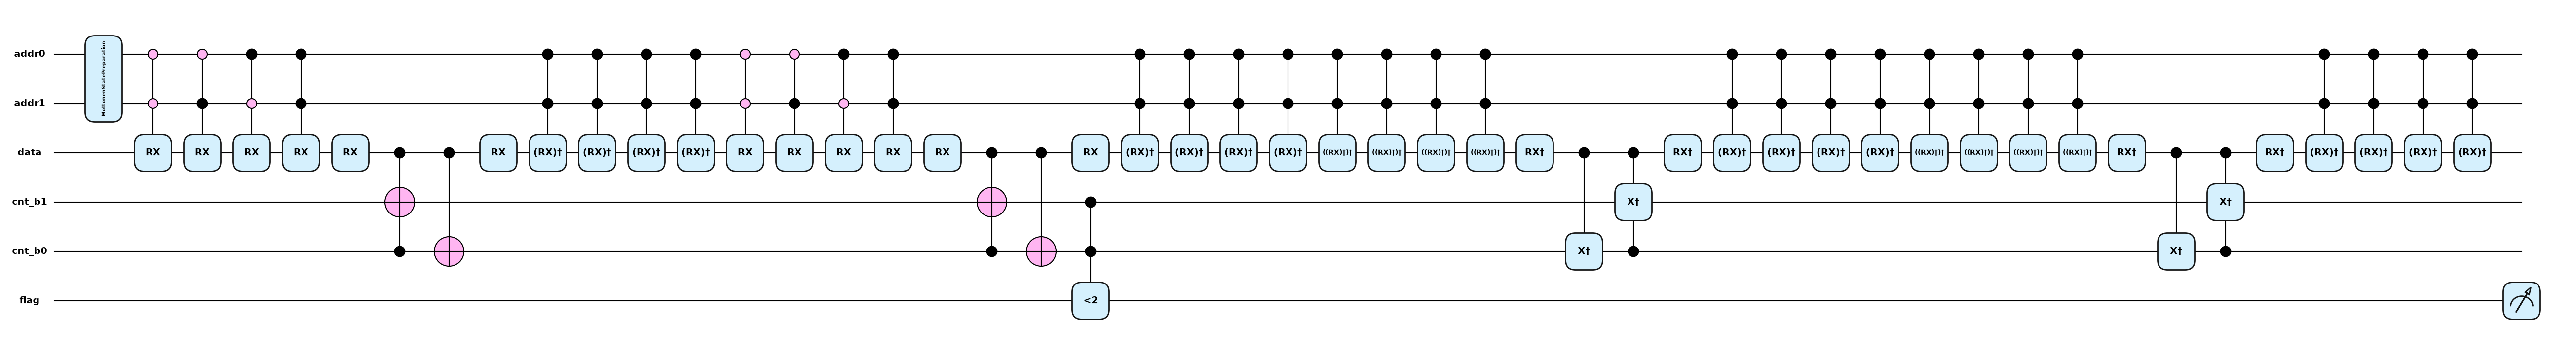

toy circuit: 6 qubits, 50 operations
P(flag=1) * M = 3.000   exact neighbour count = 3
 keys M  qubits  ops per A
     32      12      2,274
    256      15     16,610
   1024      17     65,762
   2048      18   (one half of the trained memory; ops grow linearly in M)


In [13]:
import pennylane as qml

toy_codes = np.array([[0, 0], [1, 1], [0, 1], [1, 0]])   # 4 stored keys, 2-bit LSH codes
toy_query = np.array([0, 1])
toy = ae.QRAMLayout.for_memory(len(toy_codes), toy_codes.shape[1], 1)
toy_args = ae.qram_args(toy_codes, toy_query, toy)


@qml.qnode(qml.device("default.qubit", wires=toy.n_wires))
def toy_A(s, ka, qa):
    ae.qram_A(toy, s, ka, qa)
    return qml.probs(wires=[toy.flag])


wire_names = {w: f"addr{i}" for i, w in enumerate(toy.idx)}
wire_names[toy.data] = "data"
wire_names.update({w: f"cnt_b{toy.c - 1 - i}" for i, w in enumerate(toy.cnt)})   # cnt is stored MSB first
wire_names[toy.flag] = "flag"
toy_tape = qml.workflow.construct_tape(toy_A, level="top")(*toy_args)
[toy_tape], _ = qml.map_wires(toy_tape, wire_names)

with plt.rc_context():   # PennyLane's drawing style edits matplotlib's global rcParams
    fig, _ = qml.drawer.tape_mpl(toy_tape, wire_order=list(wire_names.values()), style="pennylane")
    fig.savefig(config.output_root / "qram_oracle_A.png", dpi=150, bbox_inches="tight")
    plt.show()

exact = int(((toy_codes != toy_query).sum(1) <= toy.radius).sum())
print(f"toy circuit: {toy.n_wires} qubits, {len(toy_tape.operations)} operations")
print(f"P(flag=1) * M = {toy_A(*toy_args)[1] * len(toy_codes):.3f}   exact neighbour count = {exact}")

# Size of the same circuit at the code length / radius used in training (top-level operations, one application of A)
print(f"{'keys M':>7s} {'qubits':>7s} {'ops per A':>10s}")
for M_ in (32, 256, 1024):
    res = ae.qram_resources(M_, L_BITS, RADIUS)
    print(f"{M_:7d} {res['qubits']:7d} {res['ops_per_A']:10,d}")
full = ae.QRAMLayout.for_memory(config.memory_slots // 2, L_BITS, RADIUS)
print(f"{config.memory_slots // 2:7d} {full.n_wires:7d}   (one half of the trained memory; ops grow linearly in M)")

## 8. Notes

* **Wall-clock time is not a quantum speed-up measurement.** The `analytic` backend computes the neighbour flags
  classically (O(MD) per query) and then samples ideal-device statistics. The quantity that would carry over to
  hardware is the **Grover-call count** reported in section 6.
* **Why the two models use different setups.** Measured on the 3000-step checkpoints of earlier runs (one seed each):

  | memory / MI | baseline Fréchet / IS | QAE Fréchet / IS | distinct live real keys |
  |---|---|---|---|
  | nearest-slot memory, contrastive MI × 1.0 (QAE's setup) | 1241 / 1.04 | **60 / 7.36** | ~1450 of 1587 |
  | paper EM memory, cosine MI × 0.01 (baseline's setup) | **47-97 / 6.1-6.4** | 2368 / 1.00 | 1 of 128 |
  | paper EM memory, contrastive MI × 1.0 | 986 / 1.29 | 484 / 3.06 | 1 of 128 |

  The paper's EM step moves all 128 same-label candidates toward each new feature by the same fraction
  $\gamma/(\alpha h+\gamma)$, which is close to 1 while $h$ is small, so after a few steps every live real key is the
  same vector, and every live fake key another. The authors' code (`whyjay/memoryGAN`, `models/memory.py`) uses the
  same update. The cosine/vMF discriminator survives this: with one real and one fake prototype it is a linear
  real/fake head on the encoder, and the model trains as an ordinary GAN that ignores its key (which is also why the
  larger noise size helped it). A neighbour count against 128 copies of one key is always 0 or 128, so the QAE
  discriminator carries no information. The nearest-slot memory keeps distinct keys, which the count needs, but the
  cosine discriminator overpowers its generator there.
* **Open:** a write rule that keeps keys distinct *and* suits the cosine discriminator (e.g. the EM step restricted to
  the few nearest same-label slots) would let both models share one setup, which would make the comparison cleaner.
* **Still classical in the AE model:** the `write` rule, key sampling and the MI term. None of them can be expressed as
  a single count.